<a href="https://colab.research.google.com/github/Rui-Ping-See/MMA3001-Project-Prediction-Occupied-Unoccupied/blob/main/Project_3001.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Can environmental sensor measurements be used to predict whether a room is occupied or unoccupied?**

### The environmental measurements used are CO2 concentration, temperature and humidity. The output is the room occupancy status, represented as occupied (1) or unoccupied (0).

### The project only classifies the room as occupied or unoccupied and does not estimate the number of people present.

## **Input & Output:**

### Import the Dataset

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import zipfile
import csv

In [3]:
from google.colab import files

# upload the 3 files
uploaded = files.upload()

Saving Sensor ID and Locations.xlsx to Sensor ID and Locations.xlsx
Saving 5occupancySensor_MayToDec2024_9MRows.zip to 5occupancySensor_MayToDec2024_9MRows.zip
Saving 5EnvSensor_MayToDec2024_180kRows.zip to 5EnvSensor_MayToDec2024_180kRows.zip


### Read '5EnvSensor_MayToDec2024_180kRows.zip' file

In [4]:
env_zip = '5EnvSensor_MayToDec2024_180kRows.zip'

with zipfile.ZipFile(env_zip, 'r') as z:
    print(z.namelist())

['5EnvSensor_MayToDec2024_180kRows.csv']


In [5]:
with zipfile.ZipFile(env_zip, 'r') as z:
    filename = z.namelist()[0]

    with z.open(filename) as file:
        reader = csv.reader(line.decode('utf-8') for line in file)

        for i, row in enumerate(reader):
            print(row)

            if i == 5:
                break

['id', 'sensorid', 'devicetype', 'jsondata', 'status', 'processing_errors', 'createdate', 'processdate']
['2', '6012002000241', 'env', '[{"values": [{"time": 1702273965, "value": 4.1875}], "variable": {"id": 66, "name": "Battery", "unit": "V", "source": 0, "structure": 32834}}, {"values": [{"time": 1702273965, "value": 603}], "variable": {"id": 67, "name": "Carbon dioxide", "unit": "ppm", "source": 0, "structure": 32835}}, {"values": [{"time": 1702273965, "value": 66}], "variable": {"id": 72, "name": "Humidity", "unit": "HR%", "source": 0, "structure": 32840}}, {"values": [{"time": 1702273965, "value": 6}], "variable": {"id": 70, "name": "Formaldehyde", "unit": "µg/m3", "source": 0, "structure": 32847}}, {"values": [{"time": 1702273965, "value": 1011}], "variable": {"id": 80, "name": "Pressure", "unit": "mb", "source": 0, "structure": 32848}}, {"values": [{"time": 1702273965, "value": 23.8}], "variable": {"id": 84, "name": "Temperature", "unit": "°C", "source": 0, "structure": 32852}},

### Environmental Sensor Data

The environmental sensor dataset contains environmental measurements collected by different sensors.

The main columns are:

- `sensorid`: identifies the environmental sensor.
- `devicetype`: identifies the device type.
- `jsondata`: contains the environmental measurements.
- `createdate`: records the date and time of the sensor record.
- `processdate`: records the date and time the record was processed.

The `jsondata` column contains measurements such as carbon dioxide, humidity, temperature, pressure, formaldehyde, volatile organic compounds and particulate matter.

### Read '5occupancySensor_MayToDec2024_9MRows.zip' file


In [6]:
occ_zip = '5occupancySensor_MayToDec2024_9MRows.zip'

with zipfile.ZipFile(occ_zip, 'r') as z:
    print(z.namelist())

['5occupancySensor_MayToDec2024_9MRows.csv']


In [7]:
with zipfile.ZipFile(occ_zip, 'r') as z:
    filename = z.namelist()[0]

    with z.open(filename) as file:
        reader = csv.reader(line.decode('utf-8') for line in file)

        for i, row in enumerate(reader):
            print(row)

            if i == 5:
                break

['id', 'deviceid', 'floorspaceid', 'occupancystatus', 'headcount', 'collecteddate', 'occupancystatuschangedate', 'previousoccupancystatus']
['136043', '56923747-b390-4f2a-8930-808429132266', '941f0352-bb69-47d0-a9c5-ac29eb4f7319', 'CurrentlyOccupied', '1', '2023-11-24 00:36:52+11', '2023-11-24 00:36:52+11', 'NotOccupied']
['136048', '56923747-b390-4f2a-8930-808429132266', '941f0352-bb69-47d0-a9c5-ac29eb4f7319', 'RecentlyOccupied', '0', '2023-11-24 00:37:32+11', '2023-11-24 00:37:32+11', 'CurrentlyOccupied']
['136050', '56923747-b390-4f2a-8930-808429132266', '0f3f37f8-0335-41e0-ae87-a1d677dfc7d7', 'CurrentlyOccupied', '1', '2023-11-24 00:37:32+11', '2023-11-24 00:37:32+11', 'NotOccupied']
['136052', '56923747-b390-4f2a-8930-808429132266', '941f0352-bb69-47d0-a9c5-ac29eb4f7319', 'NotOccupied', '0', '2023-11-24 00:37:52+11', '2023-11-24 00:37:52+11', 'RecentlyOccupied']
['136053', '56923747-b390-4f2a-8930-808429132266', '0f3f37f8-0335-41e0-ae87-a1d677dfc7d7', 'RecentlyOccupied', '0', '202

### Occupancy Sensor Data

The occupancy sensor dataset contains occupancy related information such as device ID, floor space ID, occupancy status, headcount and time of collection.

The occupancy status includes values such as `CurrentlyOccupied`, `RecentlyOccupied` and `NotOccupied`.

### Read 'Sensor ID and Locations.xlsx' file

In [8]:
from openpyxl import load_workbook

In [9]:
wb = load_workbook('Sensor ID and Locations.xlsx', read_only=True)

print(wb.sheetnames)

['ENV', 'OCC (Incorrect Data - SpaceFloo']


In [10]:
# run the first sheet in excel
sheet = wb[wb.sheetnames[0]]

for i, row in enumerate(sheet.iter_rows(values_only=True)):
    print(row)

    if i == 9:
        break

('Building', 'Floor/Room', 'Area', 'Physical Label', 'Sensor', 'ID')
(60.0, '1-PS01', 'Corridor', 'ES1104', 'Env', 6012003000486.0)
(69.0, '1-PS02', 'Breakout', 'ES2113', 'Env', 6012003000882.0)
(60.0, '1.40', 'Board Room', 'ES1102', 'Env', 6012003000462.0)
(60.0, '1.41', 'Open Office', 'ES1110', 'Env', 6012003000424.0)
(60.0, '1.41A', 'Focus Room 1', 'ES1101', 'Env', 6012003000448.0)
(60.0, '1.42', 'Startup Workshop', 'ES1103', 'Env', 6012003000479.0)
(60.0, '1.43', 'Startup', 'ES1105', 'Env', 6012003000493.0)
(60.0, '1.45', 'Meeting Room', 'ES1106', 'Env', 6012003000509.0)
(60.0, '1.47', 'Corridor', 'ES1107', 'Env', 6012003000516.0)


In [11]:
# run the second sheet in excel
occ_sheet = wb[wb.sheetnames[1]]

for i, row in enumerate(occ_sheet.iter_rows(values_only=True)):
    print(row)

    if i == 9:
        break

('Building', 'Floor/Room', 'Area', 'ID', 'Note', 'FloorId', 'SpaceId')
(60.0, '1-PS01', None, '8034-2812-ae89', None, '94fda9ec-e483-460e-96ce-5767c791c1c1', 'fe553808-899c-43a3-96f7-f444f41f3046')
(60.0, '1-PS01', None, '8034-2812-c28f', None, '94fda9ec-e483-460e-96ce-5767c791c1c1', 'bd7e25c4-beb5-4d17-9426-859cacfd0f03')
(60.0, '1-PS01', None, '8034-2812-bfc5', None, '94fda9ec-e483-460e-96ce-5767c791c1c1', '67235649-ade6-43d7-a216-180d6dd8e3c1')
(60.0, '1-PS01', None, '8034-2812-cc64', None, '94fda9ec-e483-460e-96ce-5767c791c1c1', '7ac9618b-5096-41a1-85d9-2db3541075e6')
(60.0, '1.38', None, '8034-2812-ecc1', None, '94fda9ec-e483-460e-96ce-5767c791c1c1', '56d7400d-7933-4e4e-9ecc-e5da4c8f991d')
(60.0, '1.39', None, 'missing', 'Missing Id', '94fda9ec-e483-460e-96ce-5767c791c1c1', '2387067e-5349-422a-a4f5-08d93ef52a6e')
(60.0, '1.40', None, '8034-285a-73d4', None, '94fda9ec-e483-460e-96ce-5767c791c1c1', 'f1bbb258-eb6b-4711-9523-5799bf87e53b')
(60.0, '1.41', None, '8034-2812-e179', None, 

In [12]:
target_id = '941f0352-bb69-47d0-a9c5-ac29eb4f7319' # first row of floorspaceid

for row in occ_sheet.iter_rows(values_only=True):
    if target_id in row:
        print(row)

In [13]:
target_id = '56923747-b390-4f2a-8930-808429132266' # first row of deviceid

for row in occ_sheet.iter_rows(values_only=True):
    if target_id in row:
        print(row)

### Occupancy Location Mapping Check

The occupancy file `deviceid` and `floorspaceid` were compared with the IDs in the second sheet of Sensor ID and Locations file.

The tested IDs were not found in the sheet. Therefore, the occupancy location sheet could not be directly used to map these occupancy records to a room using those identifiers.

### Check the Date Range of the Datasets

In [14]:
import json
from datetime import datetime, timezone

In [15]:
# Environmental dataset
env_times = []

with zipfile.ZipFile(env_zip, 'r') as z:
    filename = z.namelist()[0]

    with z.open(filename) as file:
        reader = csv.DictReader(line.decode('utf-8') for line in file)

        for row in reader:
            data = json.loads(row['jsondata'])

            time_value = data[0]['values'][0]['time']
            env_times.append(time_value)

env_start = min(env_times)
env_end = max(env_times)

print("Environmental data start:",
      datetime.fromtimestamp(env_start, timezone.utc))

print("Environmental data end:",
      datetime.fromtimestamp(env_end, timezone.utc))

Environmental data start: 2023-05-05 22:42:45+00:00
Environmental data end: 2026-04-22 13:12:41+00:00


In [16]:
# Occupancy dataset
occ_start = None
occ_end = None

with zipfile.ZipFile(occ_zip, 'r') as z:
    filename = z.namelist()[0]

    with z.open(filename) as file:
        reader = csv.DictReader(line.decode('utf-8') for line in file)

        for row in reader:
            date = datetime.fromisoformat(row['collecteddate'])

            if occ_start is None or date < occ_start:
                occ_start = date

            if occ_end is None or date > occ_end:
                occ_end = date

print("Occupancy data start:", occ_start)
print("Occupancy data end:", occ_end)

Occupancy data start: 2023-11-24 00:36:52+11:00
Occupancy data end: 2026-04-22 23:02:38+10:00


### Date Range Check

The environmental sensor data covers approximately from May 2023 to April 2026.

The occupancy sensor data covers approximately from November 2023 to April 2026.

Therefore, both datasets have an overlapping time period from approximately November 2023 to April 2026, which allows the environmental measurements and occupancy information to be compared over the same period.

### Select One Room for Initial Analysis

For the initial analysis, one room will be selected to reduce the size and complexity of the dataset.

Selected room:
- Floor/Room: 1.40
- Area: Board Room
- Environmental sensor ID: 6012003000462
- Space ID: f1bbb258-eb6b-4711-9523-5799bf87e53b

In [17]:
target_space = 'f1bbb258-eb6b-4711-9523-5799bf87e53b'

found = False

with zipfile.ZipFile(occ_zip, 'r') as z:
    filename = z.namelist()[0]

    with z.open(filename) as file:
        reader = csv.DictReader(line.decode('utf-8') for line in file)

        for row in reader:
            if row['floorspaceid'] == target_space:
                print(row)
                found = True
                break

print("Found:", found)

Found: False


### Initial Room Selection Check

Room 1.40 (Board Room) was initially considered for analysis. However, its occupancy `SpaceId` could not be found in the occupancy dataset.

Therefore, this room was not used for further analysis.

### Check Occupancy Space IDs

In [37]:
# find how many different occupancy spaces are present in the occupancy file
occupancy_spaces = set()

with zipfile.ZipFile(occ_zip, 'r') as z:
    filename = z.namelist()[0]

    with z.open(filename) as file:
        reader = csv.DictReader(line.decode('utf-8') for line in file)

        for row in reader:
            occupancy_spaces.add(row['floorspaceid'])

print("Number of different occupancy spaces:", len(occupancy_spaces))

Number of different occupancy spaces: 5


In [36]:
# check whether those occupancy values (floorspaceid) can be linked to actual rooms names
matches = []

for row in occ_sheet.iter_rows(min_row=2, values_only=True):
    space_id = row[6]

    if space_id in occupancy_spaces:
        matches.append(row)

print("Number of matching rows:", len(matches))

for row in matches[:10]:
    print(row)

Number of matching rows: 4
(60.0, 'G.20', None, '8034-2812-bfed', None, '54803c37-793b-47ed-8f25-df460ed01d48', 'cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b')
(60.0, 'G.20', None, '8034-285a-c064', None, '54803c37-793b-47ed-8f25-df460ed01d48', 'cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b')
(60.0, 'G.25', None, '8034-285a-72f0', '2.4m (Keenan Lab)', '54803c37-793b-47ed-8f25-df460ed01d48', '227f1068-9e41-469f-bef0-275f27a0bdba')
(60.0, 'G.25', None, '8034-2812-6ebd', '2.4m (Keenan Lab)', '54803c37-793b-47ed-8f25-df460ed01d48', '227f1068-9e41-469f-bef0-275f27a0bdba')


In [35]:
# check whether those room have environmental sensors
for row in sheet.iter_rows(min_row=2, values_only=True):
    if row[1] == 'G.20' or row[1] == 'G.25':
        print(row)

(60.0, 'G.20', 'Informal Breakout 1', 'ES1G01', 'Env', 6012003000141.0)
(60.0, 'G.20', 'Informal Breakout 2', 'ES1G02', 'Env', 6012003000172.0)
(60.0, 'G.20', 'Informal Breakout 3', 'ES1G03', 'Env', 6012003000189.0)
(60.0, 'G.25', 'MSM_3D Printers', 'ES1G09', 'Env', 6012003000363.0)
(60.0, 'G.25', 'MSM_Demo', 'ES1G10', 'Env', 6012003000370.0)
(60.0, 'G.25', 'MSM_CNC', 'ES1G11', 'Env', 6012003000387.0)
(60.0, 'G.25', 'MSM_Robot Charging', 'ES1G12', 'Env', 6012003000394.0)
(60.0, 'G.25', 'MSM_Central', 'ES1G14', 'Env', 6012003000646.0)


### Occupancy and Environmental Room Matching

*   The occupancy dataset contains 5 different `floorspaceid` values.

*   These `floorspaceid` values were compared with the `SpaceId` values in the occupancy sheet of the Sensor ID and Locations file to identify the corresponding room names.

*   Matching rooms were found for G.20 and G.25. The environmental sensor sheet was then checked to confirm that these rooms also contain environmental sensors. Therefore, G.20 and G.25 can potentially be used to relate environmental sensor measurements with occupancy information.

### Selected Room for Analysis

G.25 was selected for the initial room based analysis because occupancy information and environmental sensor IDs were available for the room in the mapping file.

In [21]:
selected_room = 'G.25'
selected_space_id = '227f1068-9e41-469f-bef0-275f27a0bdba'

In [22]:
env_sensor_ids = []

for row in sheet.iter_rows(min_row=2, values_only=True):
    if row[1] == selected_room:
        env_sensor_ids.append(str(int(row[5])))

print("Environmental sensor IDs for", selected_room)
print(env_sensor_ids)

Environmental sensor IDs for G.25
['6012003000363', '6012003000370', '6012003000387', '6012003000394', '6012003000646']


G.25 contains five environmental sensors. Their sensor IDs were identified from the ENV sheet (first sheet in the excel) so that only environmental measurements from the selected room can be extracted for further analysis.

### Selected Inputs and Output

The input variables are:

*   Carbon dioxide concentration, measured in ppm
*   Temperature, measured in °C
*   Humidity, measured in HR%

The output variable is occupancy status.

For the computational model, occupancy status is converted into two binary classes:

*   1 = Occupied
*   0 = Unoccupied

The final analysis uses a selected environmental sensor and occupancy-space pair that was identified during the data preparation process.

### Data Used for Final Analysis

Environmental data is taken from the environmental `sensorid` value.

Occupancy data is taken from the `floorspaceid`.

The environmental measurements and occupancy records will be matched later using their timestamps rounded to the same minute.

Only timestamps available in both datasets are included in the final combined dataset.

## **Data Preparation**

### Check G.25 Occupancy Status

In [23]:
# For G.25, check how many records are CurrentlyOccupied, RecentlyOccupied, and NotOccupied?
status_count = {}

with zipfile.ZipFile(occ_zip, 'r') as z:
    filename = z.namelist()[0]

    with z.open(filename) as file:
        reader = csv.DictReader(line.decode('utf-8') for line in file)

        for row in reader:
            if row['floorspaceid'] == selected_space_id:
                status = row['occupancystatus']

                if status in status_count:
                    status_count[status] += 1
                else:
                    status_count[status] = 1

print(status_count)

{'NotOccupied': 76248, 'CurrentlyOccupied': 1311089, 'RecentlyOccupied': 113057}


The occupancy data for G.25 contains three states: `CurrentlyOccupied`, `RecentlyOccupied`, and `NotOccupied`.

For the initial binary classification, `CurrentlyOccupied` will represent occupied and `NotOccupied` will represent unoccupied. `RecentlyOccupied` will initially be excluded because it does not clearly indicate whether the room is currently occupied.

### Prepare Binary Occupancy Output

In [24]:
# converting the occupancy labels into binary numbers ( 1 or 0 )
occupancy_time = []
occupancy_binary = []

with zipfile.ZipFile(occ_zip, 'r') as z:
    filename = z.namelist()[0]

    with z.open(filename) as file:
        reader = csv.DictReader(line.decode('utf-8') for line in file)

        for row in reader:
            if row['floorspaceid'] == selected_space_id:

                if row['occupancystatus'] == 'CurrentlyOccupied':
                    occupancy_time.append(row['collecteddate'])
                    occupancy_binary.append(1)

                elif row['occupancystatus'] == 'NotOccupied':
                    occupancy_time.append(row['collecteddate'])
                    occupancy_binary.append(0)

In [25]:
print("Total number of binary occupancy records:", len(occupancy_binary))
print("Occupied:", occupancy_binary.count(1))
print("Unoccupied:", occupancy_binary.count(0))

Total number of binary occupancy records: 1387337
Occupied: 1311089
Unoccupied: 76248


### Extract G.25 Environmental Data ( from the environment zip file )

In [26]:
env_time = []
env_sensor = []
env_co2 = []
env_temperature = []
env_humidity = []

with zipfile.ZipFile(env_zip, 'r') as z:
    filename = z.namelist()[0]

    with z.open(filename) as file:
        reader = csv.DictReader(line.decode('utf-8') for line in file)

        for row in reader:

            # Only use environmental sensors located in G.25
            if row['sensorid'] in env_sensor_ids:

                data = json.loads(row['jsondata'])

                co2 = None
                temperature = None
                humidity = None
                measurement_time = None

                for item in data:

                    name = item['variable']['name']
                    value = item['values'][0]['value']

                    if measurement_time is None:
                        measurement_time = item['values'][0]['time']

                    if name == 'Carbon dioxide':
                        co2 = value

                    elif name == 'Temperature':
                        temperature = value

                    elif name == 'Humidity':
                        humidity = value

                if co2 is not None and temperature is not None and humidity is not None:

                    env_time.append(measurement_time)
                    env_sensor.append(row['sensorid'])
                    env_co2.append(co2)
                    env_temperature.append(temperature)
                    env_humidity.append(humidity)

In [27]:
found_sensor_ids = set()

with zipfile.ZipFile(env_zip, 'r') as z:
    filename = z.namelist()[0]

    with z.open(filename) as file:
        reader = csv.DictReader(line.decode('utf-8') for line in file)

        for row in reader:
            if row['sensorid'] in env_sensor_ids:
                found_sensor_ids.add(row['sensorid'])

print("G.25 sensor IDs from Excel:")
print(env_sensor_ids)

print("G.25 sensor IDs found in environmental file:")
print(found_sensor_ids)

G.25 sensor IDs from Excel:
['6012003000363', '6012003000370', '6012003000387', '6012003000394', '6012003000646']
G.25 sensor IDs found in environmental file:
set()


`set()` show that the sensor IDs that the Excel file says belong to G.25 do not actually appear in the environmental CSV. This shows that the original G.25 approach does not work. So I decided to change a room instead of G.25.

In [28]:
# check what is the sensor ID for G.20 in excel sheet 1
g20_sensor_ids = []

for row in sheet.iter_rows(min_row=2, values_only=True):
    if row[1] == 'G.20':
        g20_sensor_ids.append(str(int(row[5])))

print("G.20 sensor IDs from Excel:")
print(g20_sensor_ids)

G.20 sensor IDs from Excel:
['6012003000141', '6012003000172', '6012003000189']


In [29]:
# check is there G.20 sensor ID in environmental sensor file
found_g20_ids = set()

with zipfile.ZipFile(env_zip, 'r') as z:
    filename = z.namelist()[0]

    with z.open(filename) as file:
        reader = csv.DictReader(line.decode('utf-8') for line in file)

        for row in reader:
            if row['sensorid'] in g20_sensor_ids:
                found_g20_ids.add(row['sensorid'])

print("G.20 sensor IDs found in environmental file:")
print(found_g20_ids)

G.20 sensor IDs found in environmental file:
set()


G.20 and G.25 both room show that `set()` has nothing means that the room to sensor mapping in the Excel file does not line up properly with the environmental CSV.

In [30]:
# check which environmental sensor IDs actually exist in the environmental sensor file?
env_file_sensor_ids = set()

with zipfile.ZipFile(env_zip, 'r') as z:
    filename = z.namelist()[0]

    with z.open(filename) as file:
        reader = csv.DictReader(line.decode('utf-8') for line in file)

        for row in reader:
            env_file_sensor_ids.add(row['sensorid'])

print("Number of different sensor IDs in environmental file:",
      len(env_file_sensor_ids))

Number of different sensor IDs in environmental file: 5


In [34]:
# check whether any of those actual environmental sensor IDs appear in the Excel mapping

env_matches = []

for row in sheet.iter_rows(min_row=2, values_only=True):
    sensor_id = str(int(row[5]))

    if sensor_id in env_file_sensor_ids:
        env_matches.append(row)

print("Number of matching environmental sensors:", len(env_matches))

for row in env_matches:
    print(row)

Number of matching environmental sensors: 1
(60.0, 'G.38', 'Compactus_upper', 'EMS107', 'Env', 6012002000869.0)


In [32]:
# check the occupancy for G.38
for row in occ_sheet.iter_rows(min_row=2, values_only=True):
    if row[1] == 'G.38':
        print(row)

In [33]:
# checks how many different occupancy devices exist in the whole occupancy file
occupancy_device_ids = set()

with zipfile.ZipFile(occ_zip, 'r') as z:
    filename = z.namelist()[0]

    with z.open(filename) as file:
        reader = csv.DictReader(line.decode('utf-8') for line in file)

        for row in reader:
            occupancy_device_ids.add(row['deviceid'])

print("Number of different occupancy device IDs:",
      len(occupancy_device_ids))

print(occupancy_device_ids)

Number of different occupancy device IDs: 1
{'56923747-b390-4f2a-8930-808429132266'}


Only one of the environmental sensor IDs found in the environmental CSV could be matched to the Excel mapping file. This suggests that the provided room to sensor mapping is incomplete or does not fully correspond with the sensor IDs contained in the environmental dataset.

In [38]:
# check whether the occupancy device ID from the CSV exists in the Excel mapping
# go through the second excel sheet and check whether its ID column matches this occupancy deviceid

target_device_id = '56923747-b390-4f2a-8930-808429132266'

found_match = False

for row in occ_sheet.iter_rows(min_row=2, values_only=True):
    if row[3] == target_device_id:
        print("Matching occupancy mapping found:")
        print(row)
        found_match = True

if not found_match:
    print("No matching occupancy device ID found in the Excel mapping.")

No matching occupancy device ID found in the Excel mapping.


The occupancy device ID found in the occupancy CSV could not be matched to the provided Excel mapping file. This further indicates that the mapping information is incomplete or does not fully correspond with the IDs contained in the actual datasets.

### Verify Available Environmental and Occupancy IDs

The original room based approach could not be continued because the sensor IDs linked to the selected rooms were not found in the actual datasets. Therefore, the environmental sensor IDs and occupancy space IDs that were actually available in each of the files. These IDs were then compared with the Excel mapping file to see whether a reliable room match could still be identified.

In [39]:
# find the environmental sensorid that were actually present in environment file
print("Environmental sensor IDs:")
for sensor_id in env_file_sensor_ids:
    print(sensor_id)

Environmental sensor IDs:
6012002000869
6012002000777
6012002000227
6012002000326
6012002000241


In [40]:
# find the occupancy floorspaceid that were actually present in occupancy file
print("Occupancy floorspace IDs:")
for space_id in occupancy_spaces:
    print(space_id)

Occupancy floorspace IDs:
0f3f37f8-0335-41e0-ae87-a1d677dfc7d7
3e5a14df-4b14-4ea5-bb9d-46577c6dc9c8
941f0352-bb69-47d0-a9c5-ac29eb4f7319
227f1068-9e41-469f-bef0-275f27a0bdba
cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b


The initial room G.25 could not be used because its environmental sensor IDs were not found in the environmental sensor dataset. G.20 showed the same issue.

Checking the environmental dataset found five unique environmental sensor IDs. Only one of these could be matched to the ENV location excel sheet, which identified the room is G.38. However, G.38 could not be identified in the occupancy location mapping.

Therefore, a common room between the environmental and occupancy datasets has not yet been reliably identified, so this apporoach need to be stop here.

In [41]:
# double check whether the other 4 environmental sensor IDs can also be linked to a room in the Excel mapping file
for sensor_id in env_file_sensor_ids:
    found = False

    for row in sheet.iter_rows(min_row=2, values_only=True):
        excel_id = str(int(row[5]))

        if excel_id == sensor_id:
            print(sensor_id, "->", row[1], row[2])
            found = True

    if found == False:
        print(sensor_id, "-> No room found")

6012002000869 -> G.38 Compactus_upper
6012002000777 -> No room found
6012002000227 -> No room found
6012002000326 -> No room found
6012002000241 -> No room found


### Another Approach - Data-Driven Sensor and Occupancy Matching

In [42]:
# prepare environmental sensor data by storing CO2, temperature and humidity for each sensor ID at each minute
env_data = {}

with zipfile.ZipFile(env_zip, 'r') as z:
    filename = z.namelist()[0]

    with z.open(filename) as file:
        reader = csv.DictReader(line.decode('utf-8') for line in file)

        for row in reader:
            sensor_id = row['sensorid']
            data = json.loads(row['jsondata'])

            co2 = None
            temperature = None
            humidity = None
            measurement_time = None

            for item in data:
                name = item['variable']['name']

                if len(item['values']) > 0 and 'value' in item['values'][0]:
                    value = item['values'][0]['value']
                else:
                    continue

                if measurement_time is None:
                    measurement_time = item['values'][0]['time']

                if name == 'Carbon dioxide':
                    co2 = value
                elif name == 'Temperature':
                    temperature = value
                elif name == 'Humidity':
                    humidity = value

            if co2 is not None and temperature is not None and humidity is not None:

                # Convert time into minutes
                minute = measurement_time // 60

                if sensor_id not in env_data:
                    env_data[sensor_id] = {}

                env_data[sensor_id][minute] = [co2, temperature, humidity]

print("Number of environmental sensors:", len(env_data))

for sensor_id in env_data:
    print(sensor_id, f"{len(env_data[sensor_id])} measurements")

Number of environmental sensors: 5
6012002000241 2 measurements
6012002000326 29039 measurements
6012002000777 1 measurements
6012002000869 13800 measurements
6012002000227 1 measurements


In [43]:
# prepare the occupancy data by grouping each occupancy space by minute
# converting the occupancy status into 1 = occupied and 0 = unoccupied

occ_data = {}

with zipfile.ZipFile(occ_zip, 'r') as z:
    filename = z.namelist()[0]

    with z.open(filename) as file:
        reader = csv.DictReader(line.decode('utf-8') for line in file)

        for row in reader:
            space_id = row['floorspaceid']
            status = row['occupancystatus']

            # Only use clear occupied and unoccupied records
            if status == 'CurrentlyOccupied' or status == 'NotOccupied':

                date = datetime.fromisoformat(row['collecteddate'])

                # Convert time into minutes
                minute = int(date.timestamp() // 60)

                if status == 'CurrentlyOccupied':
                    occupancy = 1
                else:
                    occupancy = 0

                if space_id not in occ_data:
                    occ_data[space_id] = {}

                occ_data[space_id][minute] = occupancy

print("Number of unique occupancy spaces:", len(occ_data))

for space_id in occ_data:
    print(space_id, f"{len(occ_data[space_id])} occupancy minute records")

Number of unique occupancy spaces: 5
941f0352-bb69-47d0-a9c5-ac29eb4f7319 391699 occupancy minute records
0f3f37f8-0335-41e0-ae87-a1d677dfc7d7 425106 occupancy minute records
227f1068-9e41-469f-bef0-275f27a0bdba 352102 occupancy minute records
cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b 299097 occupancy minute records
3e5a14df-4b14-4ea5-bb9d-46577c6dc9c8 159307 occupancy minute records


### Check Time Overlap Between Environmental Sensors and Occupancy Spaces

Both environmental sensor data and occupancy data are available, but there is no reliable mapping showing which environmental sensor ID corresponds to which occupancy space ID. So, the only common thing they have is time. Therfore, time will be used.

If an environmental sensor and an occupancy space contain measurements recorded at the same time, their data can potentially be matched for further analysis. However, time overlap alone does not confirm that both sensors are from the same physical room.

In [44]:
print(f"{'ENV Sensor ID':<18}"f"{'OCC Space ID':<40}"f"{'Common times'}")

print("-" * 70)

for sensor_id in env_data:

    for space_id in occ_data:

        env_times = set(env_data[sensor_id].keys())
        occ_times = set(occ_data[space_id].keys())

        common_times = env_times.intersection(occ_times)

        print(f"{sensor_id:<18}"f"{space_id:<40}"f"{len(common_times):.1f}")

ENV Sensor ID     OCC Space ID                            Common times
----------------------------------------------------------------------
6012002000241     941f0352-bb69-47d0-a9c5-ac29eb4f7319    2.0
6012002000241     0f3f37f8-0335-41e0-ae87-a1d677dfc7d7    0.0
6012002000241     227f1068-9e41-469f-bef0-275f27a0bdba    0.0
6012002000241     cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b    0.0
6012002000241     3e5a14df-4b14-4ea5-bb9d-46577c6dc9c8    0.0
6012002000326     941f0352-bb69-47d0-a9c5-ac29eb4f7319    8300.0
6012002000326     0f3f37f8-0335-41e0-ae87-a1d677dfc7d7    7818.0
6012002000326     227f1068-9e41-469f-bef0-275f27a0bdba    8655.0
6012002000326     cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b    7343.0
6012002000326     3e5a14df-4b14-4ea5-bb9d-46577c6dc9c8    0.0
6012002000777     941f0352-bb69-47d0-a9c5-ac29eb4f7319    0.0
6012002000777     0f3f37f8-0335-41e0-ae87-a1d677dfc7d7    0.0
6012002000777     227f1068-9e41-469f-bef0-275f27a0bdba    0.0
6012002000777     cca1ac3e-f81f-4ebb-aa2

Environment sensor ID of `6012002000326` and `6012002000869` were selected for further comparison because they have a large number of overlapping timestamps with the available occupancy spaces.

### Compare Environmental Measurements for Occupied and Unoccupied Periods

In [45]:
print(f"{'ENV Sensor':<15}"f"{'OCC Space ID':<38}"f"{'Occupied CO2':<15}"f"{'Unoccupied CO2':<17}"f"{'Difference (Occ - Un)':<12}")

print("-" * 107)

for sensor_id in env_data:

    for space_id in occ_data:

        occupied_co2 = []
        unoccupied_co2 = []

        common_times = set(env_data[sensor_id].keys()).intersection(occ_data[space_id].keys())

        for time in common_times:

            co2 = env_data[sensor_id][time][0]
            occupancy = occ_data[space_id][time]

            if occupancy == 1:
                occupied_co2.append(co2)

            elif occupancy == 0:
                unoccupied_co2.append(co2)

        if len(occupied_co2) > 0 and len(unoccupied_co2) > 0:

            occupied_mean = np.mean(occupied_co2)
            unoccupied_mean = np.mean(unoccupied_co2)
            difference = occupied_mean - unoccupied_mean

            print(f"{sensor_id:<15}"f"{space_id:<38}"f"{occupied_mean:<15.1f}"f"{unoccupied_mean:<17.1f}"f"{difference:<12.1f}")

ENV Sensor     OCC Space ID                          Occupied CO2   Unoccupied CO2   Difference (Occ - Un)
-----------------------------------------------------------------------------------------------------------
6012002000326  941f0352-bb69-47d0-a9c5-ac29eb4f7319  435.0          442.6            -7.6        
6012002000326  0f3f37f8-0335-41e0-ae87-a1d677dfc7d7  434.1          439.4            -5.3        
6012002000326  227f1068-9e41-469f-bef0-275f27a0bdba  438.1          442.4            -4.3        
6012002000326  cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b  434.2          440.1            -5.9        
6012002000869  941f0352-bb69-47d0-a9c5-ac29eb4f7319  503.9          473.6            30.3        
6012002000869  0f3f37f8-0335-41e0-ae87-a1d677dfc7d7  496.5          470.1            26.4        
6012002000869  227f1068-9e41-469f-bef0-275f27a0bdba  496.9          471.0            25.9        
6012002000869  cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b  501.0          480.1            20.9        
6

### Compare CO2, Temperature and Humidity for Each Possible Pair

In [47]:
# compare each environmental sensor with each occupancy space using common timestamps,
# calculate the difference in CO2, temperature and humidity between occupied and unoccupied periods

print(f"{'ENV Sensor':<18}"f"{'OCC Space ID':<40}"f"{'Occ':<10}"f"{'Unocc':<10}"f"{'CO2 Diff (Occ - Un)':<25}"f"{'Temp Diff (Occ - Un)':<25}"f"{'Humidity Diff (Occ - Un)':<25}")

print("-" * 155)

for sensor_id in env_data:

    for space_id in occ_data:

        occupied_co2 = []
        unoccupied_co2 = []

        occupied_temp = []
        unoccupied_temp = []

        occupied_humidity = []
        unoccupied_humidity = []

        common_times = set(env_data[sensor_id].keys()).intersection(occ_data[space_id].keys())

        for time in common_times:

            co2 = env_data[sensor_id][time][0]
            temperature = env_data[sensor_id][time][1]
            humidity = env_data[sensor_id][time][2]

            occupancy = occ_data[space_id][time]

            if occupancy == 1:
                occupied_co2.append(co2)
                occupied_temp.append(temperature)
                occupied_humidity.append(humidity)

            elif occupancy == 0:
                unoccupied_co2.append(co2)
                unoccupied_temp.append(temperature)
                unoccupied_humidity.append(humidity)

        if len(occupied_co2) > 0 and len(unoccupied_co2) > 0:

            co2_difference = (
                np.mean(occupied_co2) - np.mean(unoccupied_co2))

            temp_difference = (
                np.mean(occupied_temp) - np.mean(unoccupied_temp))

            humidity_difference = (
                np.mean(occupied_humidity) - np.mean(unoccupied_humidity))

            print(f"{sensor_id:<18}"f"{space_id:<40}"f"{len(occupied_co2):<10}"f"{len(unoccupied_co2):<10}"f"{co2_difference:<25.1f}"f"{temp_difference:<25.2f}"f"{humidity_difference:<25.2f}")

ENV Sensor        OCC Space ID                            Occ       Unocc     CO2 Diff (Occ - Un)      Temp Diff (Occ - Un)     Humidity Diff (Occ - Un) 
-----------------------------------------------------------------------------------------------------------------------------------------------------------
6012002000326     941f0352-bb69-47d0-a9c5-ac29eb4f7319    7511      789       -7.6                     0.50                     -1.36                    
6012002000326     0f3f37f8-0335-41e0-ae87-a1d677dfc7d7    6585      1233      -5.3                     0.35                     -1.25                    
6012002000326     227f1068-9e41-469f-bef0-275f27a0bdba    6800      1855      -4.3                     -0.09                    -1.49                    
6012002000326     cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b    6861      482       -5.9                     0.63                     -0.92                    
6012002000869     941f0352-bb69-47d0-a9c5-ac29eb4f7319    4240      563   

### Select a Data-Driven Sensor and Occupancy Pair

Because the provided room mapping could not reliably link the environmental and occupancy datasets, the possible environmental sensor and occupancy space combinations were compared using their overlapping timestamps and environmental measurements.

Environmental sensor `6012002000869` showed a clearer difference in CO2 levels between occupied and unoccupied periods compared with the other environmental sensors.  The CO2 range difference is between 20 to 40.

Occupancy space `941f0352-bb69-47d0-a9c5-ac29eb4f7319` was selected because it had a good number of both occupied and unoccupied matching records and showed a clear difference in CO2 levels.

This pair will be used for the initial analysis. The pairing is based on the data and is not treated as a confirmed physical room mapping.

### Create the Combined Dataset

In [48]:
selected_env_sensor = '6012002000869'
selected_occ_space = '941f0352-bb69-47d0-a9c5-ac29eb4f7319'

In [49]:
# combine the selected environmental sensor and occupancy space using common timestamps
# to create the final dataset for model training and testing

combined_time = []
combined_co2 = []
combined_temperature = []
combined_humidity = []
combined_occupancy = []

common_times = set(env_data[selected_env_sensor].keys()).intersection(occ_data[selected_occ_space].keys())

for time in common_times:

    co2 = env_data[selected_env_sensor][time][0]
    temperature = env_data[selected_env_sensor][time][1]
    humidity = env_data[selected_env_sensor][time][2]

    occupancy = occ_data[selected_occ_space][time]

    combined_time.append(time)
    combined_co2.append(co2)
    combined_temperature.append(temperature)
    combined_humidity.append(humidity)
    combined_occupancy.append(occupancy)

print("Number of matched records:", len(combined_occupancy))
print("Occupied:", combined_occupancy.count(1))
print("Unoccupied:", combined_occupancy.count(0))

Number of matched records: 4803
Occupied: 4240
Unoccupied: 563


In [50]:
# display the first 5 matched records to check the final combined dataset

print(f"{'Time':<15}"f"{'CO2':<10}"f"{'Temperature':<15}"f"{'Humidity':<12}"f"{'Occupancy':<10}")

print("-" * 65)

for i in range(5):
    print(f"{combined_time[i]:<15}"f"{combined_co2[i]:<10}"f"{combined_temperature[i]:<15}"f"{combined_humidity[i]:<12}"f"{combined_occupancy[i]:<10}")

Time           CO2       Temperature    Humidity    Occupancy 
-----------------------------------------------------------------
28516355       487       23.8           34          0         
28581895       450       23.5           48          1         
28491784       486       23.8           37          1         
28565515       542       23.5           42          1         
28516365       498       24             34          1         


The environmental measurements and occupancy status were matched using timestamps rounded to the same minute.

The combined dataset contains CO2, temperature and humidity as the input variables, with occupancy represented as 1 for occupied and 0 for unoccupied.

Only timestamps available in both datasets were included.

### Check Environmental Data Range

In [128]:
print("CO2:(ppm)")
print("Minimum:", min(combined_co2))
print("Maximum:", max(combined_co2))
print("Mean:", round(np.mean(combined_co2), 2))

print()

print("Temperature:(°C)")
print("Minimum:", min(combined_temperature))
print("Maximum:", max(combined_temperature))
print("Mean:", round(np.mean(combined_temperature), 2))

print()

print("Humidity:(HR%)")
print("Minimum:", min(combined_humidity))
print("Maximum:", max(combined_humidity))
print("Mean:", round(np.mean(combined_humidity), 2))

CO2:(ppm)
Minimum: 403
Maximum: 646
Mean: 500.35

Temperature:(°C)
Minimum: 19.5
Maximum: 28.5
Mean: 23.63

Humidity:(HR%)
Minimum: 26
Maximum: 74
Mean: 44.68


The ranges of CO2, temperature and humidity were checked for unusual values.

The values were within reasonable ranges, so no records were removed based on these variables at this stage.

### Visualise Environmental Measurements by Occupancy
A boxplot was used because it provides a simple way to compare the distribution of environmental measurements between occupied and unoccupied periods. It also shows the median values, the spread of the data, any overlap between the two occupancy groups and any outliers. This makes it easy to see whether the occupied and unoccupied groups have any noticeably different.

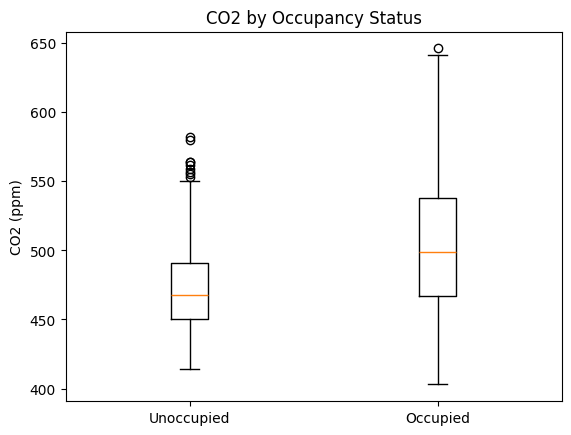

In [52]:
# CO2 box plot

occupied_co2 = []
unoccupied_co2 = []

for i in range(len(combined_occupancy)):

    if combined_occupancy[i] == 1:
        occupied_co2.append(combined_co2[i])

    else:
        unoccupied_co2.append(combined_co2[i])

plt.boxplot([unoccupied_co2, occupied_co2], tick_labels=['Unoccupied', 'Occupied'])

plt.ylabel('CO2 (ppm)')
plt.title('CO2 by Occupancy Status')
plt.show()

The CO2 values are generally higher during occupied periods. However, the two groups still overlap, which means CO2 alone may not be enough to clearly determine whether the space is occupied.

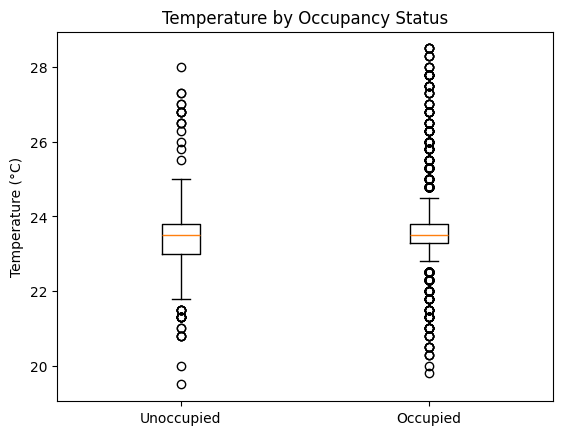

In [53]:
# Temperature box plot

occupied_temp = []
unoccupied_temp = []

for i in range(len(combined_occupancy)):

    if combined_occupancy[i] == 1:
        occupied_temp.append(combined_temperature[i])

    else:
        unoccupied_temp.append(combined_temperature[i])

plt.boxplot([unoccupied_temp, occupied_temp], tick_labels=['Unoccupied', 'Occupied'])

plt.ylabel('Temperature (°C)')
plt.title('Temperature by Occupancy Status')
plt.show()

The temperature boxplot shows that the median temperature during occupied periods and unoccupied periods are very similar. However, the difference is very small.

The two groups overlap heavily, meaning similar temperature values occur during both occupied and unoccupied periods. Therefore, temperature alone may not be a strong predictor of occupancy.

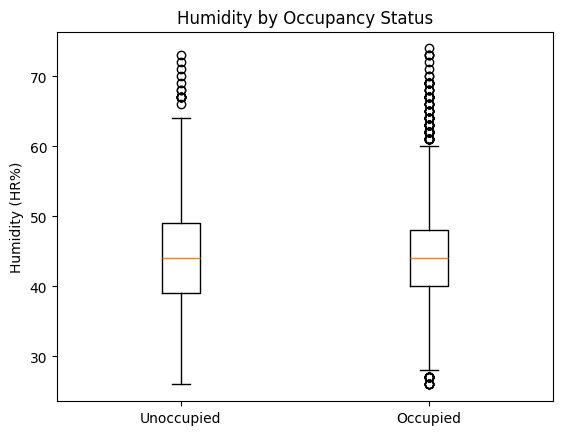

In [129]:
# Humidity box plot

occupied_humidity = []
unoccupied_humidity = []

for i in range(len(combined_occupancy)):

    if combined_occupancy[i] == 1:
        occupied_humidity.append(combined_humidity[i])

    else:
        unoccupied_humidity.append(combined_humidity[i])

plt.boxplot(
    [unoccupied_humidity, occupied_humidity],
    tick_labels=['Unoccupied', 'Occupied']
)

plt.ylabel('Humidity (HR%)')
plt.title('Humidity by Occupancy Status')
plt.show()

The humidity boxplot shows that the median humidity during occupied and unoccupied periods is very similar.

The two groups overlap heavily, meaning similar humidity values occur during both occupied and unoccupied periods. Therefore, humidity alone may not be a strong predictor of occupancy.

The boxplots were used to compare CO2, temperature and humidity during occupied and unoccupied periods.

CO2 shows the clearest difference between occupied and unoccupied periods, with generally higher CO2 levels during occupied periods.

Temperature and humidity show only small differences between the two groups, with a large amount of overlap between occupied and unoccupied periods.

This suggests that CO2 may provide more useful information for occupancy prediction than temperature or humidity individually. However, all three environmental measurements will be included in the machine learning model to determine whether combining them can improve occupancy prediction.

### Prepare Data for Machine Learning

In [55]:
x = np.column_stack((combined_co2, combined_temperature, combined_humidity))

y = np.array(combined_occupancy)

print("Shape of x:", x.shape)
print("Shape of y:", y.shape)

Shape of x: (4803, 3)
Shape of y: (4803,)


The machine learning input data, x, contains CO2, temperature and humidity measurements.

The output data, y, contains the binary occupancy status, where 1 represents occupied and 0 represents unoccupied.

Each row of x corresponds to the occupancy value at the same matched timestamp in y.

### Limitation of Sensor-Location Mapping

The location mapping provided in the dataset could not clearly confirm that the environmental sensor and occupancy space were from the same physical room.

Because of this, a suitable environmental sensor and occupancy space pair was selected using a data-driven matching approach based on the available data.


This pair is used for the analysis, but it should be treated as a possible match rather than a confirmed room match.

## **Computational Solution - Linear Regression**

### Split Data into Training and Testing Sets

In [56]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

print("Training samples:", len(x_train))
print("Testing samples:", len(x_test))

Training samples: 3842
Testing samples: 961


The dataset was split into training and testing sets. 80% of the data was used to train the model and 20% was kept for testing. Stratified splitting was used to maintain a similar proportion of occupied and unoccupied samples in both sets.

### Train Linear Regression Model

In [57]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(x_train, y_train)

LinearRegression()

### Predict Occupancy Values

In [58]:
y_pred = linear_model.predict(x_test)

print(y_pred[:10])

[0.84350706 0.82195968 0.77695082 0.9486149  0.8575856  1.02409023
 0.93377827 0.86764815 0.84658827 0.72014304]


### Actual occupancy values against the predicted Linear Regression values

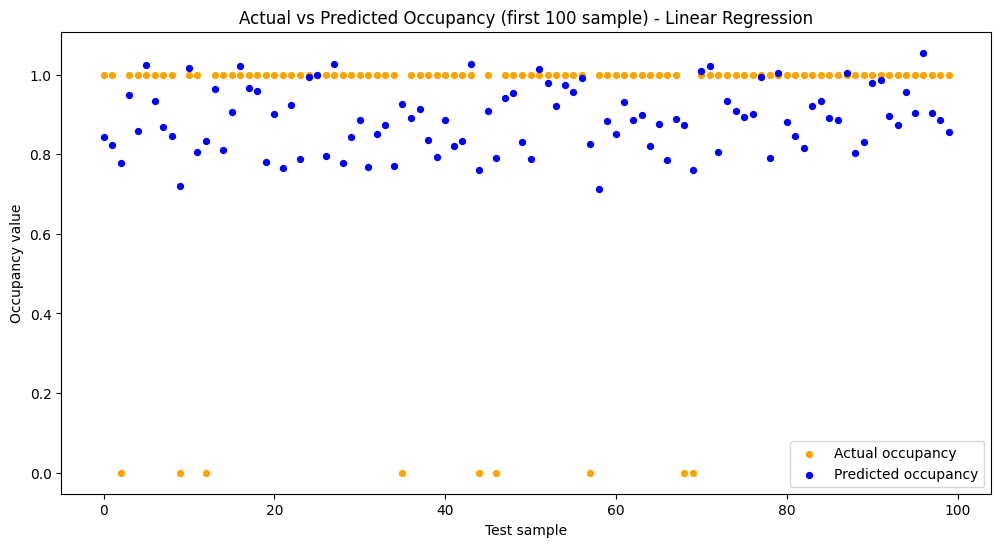

In [59]:
plt.figure(figsize=(12, 6))

plt.scatter(range(100), y_test[:100], label='Actual occupancy', s=18, color = 'orange')
plt.scatter(range(100), y_pred[:100], label='Predicted occupancy', s=18, color = 'blue')

plt.xlabel('Test sample')
plt.ylabel('Occupancy value')
plt.title('Actual vs Predicted Occupancy (first 100 sample) - Linear Regression')
plt.legend()
plt.show()

The scatter plot compares the actual occupancy values with the Linear Regression predictions for the first 100 test samples.

The predicted values mostly remain between about 0.8 and 1.0, even when some of the actual occupancy values are 0. This suggests that the Linear Regression may have difficulty predicting unoccupied periods.

### Linear Regression Performance Evaluation
The Linear Regression model was evaluated using MAE, RMSE and R².


In [60]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", f"{mae:.3f}")
print("RMSE:", f"{rmse:.3f}")
print("R2:", f"{r2:.3f}")

MAE: 0.201
RMSE: 0.313
R2: 0.058


The Linear Regression model produced an MAE of 0.201, an RMSE of 0.313 and an R^2 value of 0.058.

The MAE and RMSE show that the model’s predictions are still not very close to the actual occupancy values of 0 and 1.

The R^2 value is very low, which means the model is not doing a good job in explaining how CO2, temperature and humidity relate to occupancy.

Further evaluation is required to determine how well the model can identify occupied and unoccupied periods.

### Convert regression output into occupied/unoccupied

In [61]:
# using thredhold = 0.5
y_pred_binary = []

for value in y_pred:
    if value >= 0.5:
        y_pred_binary.append(1)
    else:
        y_pred_binary.append(0)

y_pred_binary = np.array(y_pred_binary)

print(y_pred_binary[:10])

[1 1 1 1 1 1 1 1 1 1]


A threshold of 0.5 was used because the occupancy output is represented by 0 for unoccupied and 1 for occupied. Since 0.5 is the midpoint between 0 and 1, predicted values below 0.5 are classified as unoccupied, while predicted values greater than or equal to 0.5 are classified as occupied.

In [62]:
print("Actual:   ", y_test[:10])
print("Predicted:", y_pred_binary[:10])

Actual:    [1 1 0 1 1 1 1 1 1 0]
Predicted: [1 1 1 1 1 1 1 1 1 1]


In [63]:
correct = np.sum(y_pred_binary == y_test)

accuracy = (correct / len(y_test))*100

print("Correct predictions:", correct)
print("Total test samples:", len(y_test))
print("Accuracy:", f"{accuracy:.2f}%")

Correct predictions: 848
Total test samples: 961
Accuracy: 88.24%


Linear Regression achieved about 88.2% accuracy, but it failed to identify any unoccupied samples. As model predicted everything to be occupied. Therefore, accuracy alone is misleading because the dataset is imbalanced.

In [64]:
TP = np.sum((y_test == 1) & (y_pred_binary == 1))
TN = np.sum((y_test == 0) & (y_pred_binary == 0))
FP = np.sum((y_test == 0) & (y_pred_binary == 1))
FN = np.sum((y_test == 1) & (y_pred_binary == 0))

print("True Positive:", TP)
print("True Negative:", TN)
print("False Positive:", FP)
print("False Negative:", FN)

True Positive: 848
True Negative: 0
False Positive: 113
False Negative: 0


*   True Positive (TP): actually occupied and predicted occupied
*   True Negative (TN): actually unoccupied and predicted unoccupied
*   False Positive (FP): actually unoccupied but predicted occupied
*   False Negative (FN): actually occupied but predicted unoccupied

### Calculating a Threshold from the Training Data

The initial threshold of 0.5 was selected because it is the midpoint between the occupancy values 0 and 1. However, this threshold classified all test samples as occupied.

Therefore, a new threshold was calculated using the training data. The mean predicted value for occupied samples and the mean predicted value for unoccupied samples were calculated, and the midpoint between these two values was used as the new threshold.

In [65]:
# find mean predicted value for occupied and unoccupied
y_train_pred = linear_model.predict(x_train)

occupied_pred = y_train_pred[y_train == 1]
unoccupied_pred = y_train_pred[y_train == 0]

mean_occupied_pred = np.mean(occupied_pred)
mean_unoccupied_pred = np.mean(unoccupied_pred)

print("Mean predicted value for occupied:", mean_occupied_pred)
print("Mean predicted value for unoccupied:", mean_unoccupied_pred)

Mean predicted value for occupied: 0.8903465080946097
Mean predicted value for unoccupied: 0.8265436545398476


In [66]:
# calculate new threshold
calculated_threshold = (mean_occupied_pred + mean_unoccupied_pred) / 2

print("Calculated threshold:", f"{calculated_threshold:.3f}")

Calculated threshold: 0.858


In [67]:
y_pred_new = []

for value in y_pred:
    if value >= calculated_threshold:
        y_pred_new.append(1)
    else:
        y_pred_new.append(0)

y_pred_new = np.array(y_pred_new)

In [68]:
TP_new = np.sum((y_test == 1) & (y_pred_new == 1))
TN_new = np.sum((y_test == 0) & (y_pred_new == 0))
FP_new = np.sum((y_test == 0) & (y_pred_new == 1))
FN_new = np.sum((y_test == 1) & (y_pred_new == 0))

accuracy_new = (np.mean(y_pred_new == y_test))*100

print("Accuracy:", f"{accuracy_new:.2f}%")
print("True Positive:", TP_new)
print("True Negative:", TN_new)
print("False Positive:", FP_new)
print("False Negative:", FN_new)

Accuracy: 64.10%
True Positive: 532
True Negative: 84
False Positive: 29
False Negative: 316


In [69]:
print(f"{'Performance':<20} {'Threshold = 0.5':<20} {'Threshold = 0.858'}")
print("-" * 60)
print(f"{'True Positive':<20} {TP:<20} {TP_new}")
print(f"{'True Negative':<20} {TN:<20} {TN_new}")
print(f"{'False Positive':<20} {FP:<20} {FP_new}")
print(f"{'False Negative':<20} {FN:<20} {FN_new}")
print(f"{'Accuracy':<20} {f"{accuracy:.2f}%":<20} {f"{accuracy_new:.2f}%"}")

Performance          Threshold = 0.5      Threshold = 0.858
------------------------------------------------------------
True Positive        848                  532
True Negative        0                    84
False Positive       113                  29
False Negative       0                    316
Accuracy             88.24%               64.10%


Using the calculated threshold of 0.858, the model achieved an accuracy of 64.1%. It correctly identified 84 unoccupied samples, compared with zero unoccupied samples using the initial threshold of 0.5.

The number of false positives decreased from 113 to 29, showing that the new threshold improved the model's ability to identify unoccupied periods. However, the number of false negatives increased to 316, meaning that more occupied samples were incorrectly classified as unoccupied.

The 0.5 threshold achieved a higher accuracy, but it failed to detect any unoccupied samples because it assume all test samples as occupied. This shows that a higher accuracy does not always mean the model performs better. Changing the threshold improved the detection of unoccupied periods, but reduced the detection of occupied periods, showing a trade-off between the two.

In [70]:
occupied_detection_05 = (TP / (TP + FN)) * 100
unoccupied_detection_05 = (TN / (TN + FP)) * 100

occupied_detection_new = (TP_new / (TP_new + FN_new)) * 100
unoccupied_detection_new = (TN_new / (TN_new + FP_new)) * 100

print("Threshold = 0.5")
print("Occupied correctly detected:", f"{occupied_detection_05:.1f}%")
print("Unoccupied correctly detected:", f"{unoccupied_detection_05:.1f}%")

print()

print("Threshold = 0.858")
print("Occupied correctly detected:", f"{occupied_detection_new:.1f}%")
print("Unoccupied correctly detected:", f"{unoccupied_detection_new:.1f}%")

Threshold = 0.5
Occupied correctly detected: 100.0%
Unoccupied correctly detected: 0.0%

Threshold = 0.858
Occupied correctly detected: 62.7%
Unoccupied correctly detected: 74.3%


Using the calculated threshold of 0.858 improved the ability of the model to identify unoccupied periods. Approximately 62.7% of occupied samples and 74.3% of unoccupied samples were correctly detected.

Therefore, the calculated threshold provides a more balanced result than the initial threshold of 0.5. However, the results also show that Linear Regression has limitations to predict the occupancy of a room.

## **Alternative Solution - KNN Regression**

In [71]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor

# when k = 1
knn_model = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsRegressor(n_neighbors=1))
])

knn_model.fit(x_train, y_train)

Pipeline(steps=[('scale', StandardScaler()),
                ('model', KNeighborsRegressor(n_neighbors=1))])

In [72]:
y_pred_knn = knn_model.predict(x_test)

print(y_pred_knn[:10])

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [73]:
TP_knn = np.sum((y_test == 1) & (y_pred_knn == 1))
TN_knn = np.sum((y_test == 0) & (y_pred_knn == 0))
FP_knn = np.sum((y_test == 0) & (y_pred_knn == 1))
FN_knn = np.sum((y_test == 1) & (y_pred_knn == 0))

accuracy_knn = (np.mean(y_pred_knn == y_test)) * 100

print("Accuracy:", f"{accuracy_knn:.1f}%")
print("True Positive:", TP_knn)
print("True Negative:", TN_knn)
print("False Positive:", FP_knn)
print("False Negative:", FN_knn)

Accuracy: 81.2%
True Positive: 761
True Negative: 19
False Positive: 94
False Negative: 87


*   True Positive (TP_knn): actually occupied and predicted occupied
*   True Negative (TN_knn): actually unoccupied and predicted unoccupied
*   False Positive (FP_knn): actually unoccupied but predicted occupied
*   False Negative (FN_knn): actually occupied but predicted unoccupied

### Sensitivity Analysis – Effect of different k values

In [127]:
k_values = [1, 3, 5, 7]

print(f"{'Sample':<8} {'k = 1':<10} {'k = 3':<10} {'k = 5':<10} {'k = 7':<10}")
print("-" * 48)

all_predictions = {}

for k in k_values:
    knn_model = Pipeline([("scale", StandardScaler()), ("model", KNeighborsRegressor(n_neighbors=k))])

    knn_model.fit(x_train, y_train)
    all_predictions[k] = knn_model.predict(x_test)

for i in range(10):
    print(f"{i+1:<8} " f"{all_predictions[1][i]:<10.2f} " f"{all_predictions[3][i]:<10.2f} " f"{all_predictions[5][i]:<10.2f} " f"{all_predictions[7][i]:<10.2f}")

Sample   k = 1      k = 3      k = 5      k = 7     
------------------------------------------------
1        1.00       1.00       1.00       1.00      
2        1.00       1.00       1.00       0.86      
3        1.00       1.00       0.80       0.71      
4        1.00       1.00       1.00       1.00      
5        1.00       0.33       0.60       0.71      
6        1.00       1.00       1.00       1.00      
7        1.00       1.00       1.00       1.00      
8        1.00       1.00       1.00       1.00      
9        1.00       1.00       1.00       1.00      
10       1.00       0.67       0.60       0.57      


### KNN Occupied and Unoccupied Detection Rates

In [75]:
occupied_detection_knn = (TP_knn / (TP_knn + FN_knn)) * 100
unoccupied_detection_knn = (TN_knn / (TN_knn + FP_knn)) * 100

print("Occupied correctly detected:", f"{occupied_detection_knn:.1f}%")
print("Unoccupied correctly detected:", f"{unoccupied_detection_knn:.1f}%")

Occupied correctly detected: 89.7%
Unoccupied correctly detected: 16.8%


Using KNN with (k=1), the model achieved an overall accuracy of 81.2%. It correctly detected 89.7% of the occupied samples but only 16.8% of the unoccupied samples.

When (k=1), the nearest training sample is used to make the prediction, so the output is directly either 0 or 1.

When (k) is increased to 3, 5 or 7, several nearby training samples are used and their occupancy values are averaged. Therefore, the predictions can become values between 0 and 1 instead of only 0 or 1.

For this analysis, (k=1) is kept because it gives a direct occupied or unoccupied output.

In [76]:
balanced_accuracy_knn = (occupied_detection_knn + unoccupied_detection_knn) / 2

print("Balanced accuracy:", f"{balanced_accuracy_knn:.1f}%")

Balanced accuracy: 53.3%


Balanced accuracy was calculated because the dataset contains many more occupied samples than unoccupied samples.

A high overall accuracy can be misleading if the model mainly predicts the larger occupied class correctly. Balanced accuracy gives equal importance to both occupied and unoccupied detection rates.

The balanced accuracy was 53.3%, which is much lower than the overall accuracy of 81.2%. This shows that the model performs unevenly between occupied and unoccupied samples.

### Comparison of Linear Regression and KNN

In [77]:
# Linear Regression balanced accuracy
balanced_accuracy_linear_regression = (occupied_detection_new + unoccupied_detection_new) / 2
print("Linear Regression Balanced Accuracy:", f"{balanced_accuracy_linear_regression:.2f}%")

Linear Regression Balanced Accuracy: 68.54%


In [78]:
print(f"{'Performance':<28} {'Linear Regression':<20} {'KNN k = 1':<15}")
print("-" * 65)

print(f"{'Overall accuracy':<28} {f"{accuracy_new:.2f}%":<20} {f"{accuracy_knn:.1f}%":<15}")
print(f"{'Occupied detection':<28} {f"{occupied_detection_new:.1f}%":<20} {f"{occupied_detection_knn:.1f}%":<15}")
print(f"{'Unoccupied detection':<28} {f"{unoccupied_detection_new:.1f}%":<20} {f"{unoccupied_detection_knn:.1f}%":<15}")
print(f"{'Balanced accuracy':<28} {f"{balanced_accuracy_linear_regression:.1f}%":<20} {f"{balanced_accuracy_knn:.1f}%":<15}")
print(f"{'Threshold required':<28} {'Yes':<20} {'No':<15}")
print(f"{'Output':<28} {'Continuous value':<20} {'Direct 0 or 1':<15}")

Performance                  Linear Regression    KNN k = 1      
-----------------------------------------------------------------
Overall accuracy             64.10%               81.2%          
Occupied detection           62.7%                89.7%          
Unoccupied detection         74.3%                16.8%          
Balanced accuracy            68.5%                53.3%          
Threshold required           Yes                  No             
Output                       Continuous value     Direct 0 or 1  


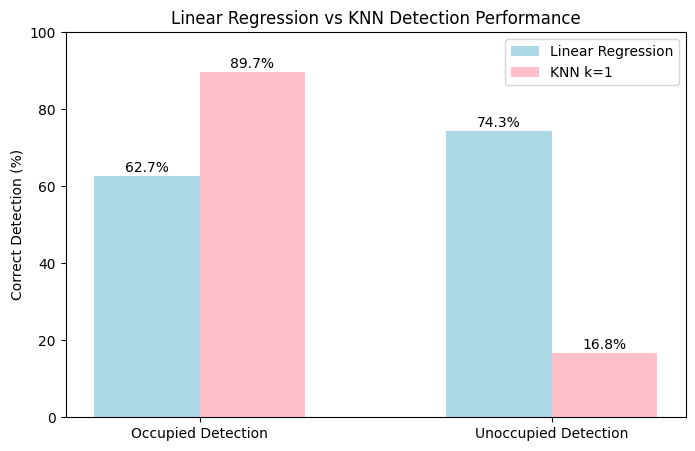

In [79]:
labels = ['Occupied Detection', 'Unoccupied Detection']

linear_values = [occupied_detection_new, unoccupied_detection_new]
knn_values = [occupied_detection_knn, unoccupied_detection_knn]

x = np.arange(len(labels))
width = 0.3

plt.figure(figsize=(8, 5))

bars1 = plt.bar(x - width/2, linear_values, width, label='Linear Regression', color='lightblue')
bars2 = plt.bar(x + width/2, knn_values, width, label='KNN k=1', color='pink')

# Add percentage values above the bars
for bar in bars1:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, f'{bar.get_height():.1f}%', ha='center')

for bar in bars2:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, f'{bar.get_height():.1f}%',ha='center')

plt.xticks(x, labels)
plt.ylabel('Correct Detection (%)')
plt.title('Linear Regression vs KNN Detection Performance')
plt.legend()
plt.ylim(0, 100)

plt.show()

A bar chart is used to visually compare the occupied and unoccupied detection rates of Linear Regression and KNN. This makes it easier to see the difference in performance between the two methods for each occupancy.

KNN achieved a higher overall accuracy of 81.2% compared with 64.1% for Linear Regression.

KNN also detected more occupied samples correctly, but it performed poorly in detecting unoccupied samples. Linear Regression detected fewer occupied samples, but it gave a more balanced result between occupied and unoccupied samples.

The balanced accuracy was higher for Linear Regression, while KNN with (k=1) has the advantage of producing a direct 0 or 1 output without requiring a threshold.

### Final Method Selection
Linear Regression was selected as the preferred method because it provided a more balanced performance between occupied and unoccupied samples.

Although KNN with k=1 can produce a direct 0 or 1 prediction without requiring a threshold, it performed poorly in detecting unoccupied samples.

Linear Regression still requires a selected threshold, which is a limitation, but based on the current results it is more suitable for identifying occupied and unoccupied periods.

## **Optimisation and Performance**

### Computational Time Comparison

In [80]:
# Linear Regression
import time

start_time_linear_regression = time.perf_counter()

linear_model.fit(x_train, y_train)
linear_prediction = linear_model.predict(x_test)

linear_time = time.perf_counter() - start_time_linear_regression

print("Linear Regression time:", f"{linear_time:.6f} seconds")

Linear Regression time: 0.003061 seconds


In [81]:
# KNN
start_time_knn = time.perf_counter()

knn_model = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsRegressor(n_neighbors=1))
])

knn_model.fit(x_train, y_train)
knn_prediction = knn_model.predict(x_test)

knn_time = time.perf_counter() - start_time_knn

print("KNN time:", f"{knn_time:.6f} seconds")

KNN time: 0.011238 seconds


In [82]:
print(f"{'Method':<22} {'Time (seconds)':<15}")
print("-" * 40)
print(f"{'Linear Regression':<22} {linear_time:.6f}s")
print(f"{'KNN k=1':<22} {knn_time:.6f}s")

Method                 Time (seconds) 
----------------------------------------
Linear Regression      0.003061s
KNN k=1                0.011238s


The computational time was measured to compare the efficiency of Linear Regression and KNN.

Linear Regression completed the training and prediction process faster than KNN in the test runs. This is expected because KNN needs to compare each test sample with the stored training samples to find the nearest neighbour.

The runtime may change slightly each time the code is run, but Linear Regression was faster than KNN in the tests carried out for this dataset.

### Calculate average runtime

In [83]:
linear_times = []
knn_times = []

for i in range(10):

    start_time_linear = time.perf_counter()

    linear_model.fit(x_train, y_train)
    linear_model.predict(x_test)

    linear_times.append(time.perf_counter() - start_time_linear)


    start_time_knn = time.perf_counter()

    knn_model = Pipeline([
        ("scale", StandardScaler()),
        ("model", KNeighborsRegressor(n_neighbors=1))
    ])

    knn_model.fit(x_train, y_train)
    knn_model.predict(x_test)

    knn_times.append(time.perf_counter() - start_time_knn)


average_linear_time = np.mean(linear_times)
average_knn_time = np.mean(knn_times)

print("Average Linear Regression time:", f"{average_linear_time:.6f} seconds")
print("Average KNN time:", f"{average_knn_time:.6f} seconds")

Average Linear Regression time: 0.001202 seconds
Average KNN time: 0.005468 seconds


The runtime was repeated 10 times and averaged to reduce the effect of small differences between individual runs.

The average runtime was approximately 0.0012 seconds for Linear Regression and 0.0055 seconds for KNN. This confirms that Linear Regression required less computational time than KNN for this dataset.

## **GitHub Testing**

In [108]:
!git clone https://github.com/Rui-Ping-See/MMA3001-Project-Prediction-Occupied-Unoccupied.git

Cloning into 'MMA3001-Project-Prediction-Occupied-Unoccupied'...
remote: Enumerating objects: 69, done.
remote: Counting objects: 100% (69/69), done.
remote: Compressing objects: 100% (68/68), done.
remote: Total 69 (delta 27), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (69/69), 185.99 KiB | 2.78 MiB/s, done.
Resolving deltas: 100% (27/27), done.


In [109]:
%cd MMA3001-Project-Prediction-Occupied-Unoccupied

/content/MMA3001-Project-Prediction-Occupied-Unoccupied/MMA3001-Project-Prediction-Occupied-Unoccupied/MMA3001-Project-Prediction-Occupied-Unoccupied


In [110]:
!pip install pytest

In [111]:
!git pull

Already up to date.


In [112]:
# Run pytest with PYTHONPATH pointing to the current directory so that 'src' is discoverable
!PYTHONPATH=. pytest

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0
rootdir: /content/MMA3001-Project-Prediction-Occupied-Unoccupied/MMA3001-Project-Prediction-Occupied-Unoccupied/MMA3001-Project-Prediction-Occupied-Unoccupied
plugins: platformdirs-4.13.5, anyio-4.15.1, typeguard-4.6.0, langsmith-0.14.11
collected 4 items                                                              

tests/test_occupancy_prediction.py ....                                  [100%]

============================== 4 passed in 2.79s ===============================


In [113]:
!PYTHONPATH=. pytest > test_report.txt

In [115]:
!cat test_report.txt

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0
rootdir: /content/MMA3001-Project-Prediction-Occupied-Unoccupied/MMA3001-Project-Prediction-Occupied-Unoccupied/MMA3001-Project-Prediction-Occupied-Unoccupied
plugins: platformdirs-4.13.5, anyio-4.15.1, typeguard-4.6.0, langsmith-0.14.11
collected 4 items

tests/test_occupancy_prediction.py ....                                  [100%]

============================== 4 passed in 2.40s ===============================


In [116]:
!pip install pdoc

In [117]:
!pdoc src/occupancy_prediction.py -o docs

In [118]:
!find docs -maxdepth 2 -type f

docs/src/occupancy_prediction.html
docs/index.html
docs/occupancy_prediction.html
docs/search.js


In [119]:
!zip -r docs.zip docs

  adding: docs/ (stored 0%)
  adding: docs/src/ (stored 0%)
  adding: docs/src/occupancy_prediction.html (deflated 83%)
  adding: docs/index.html (deflated 23%)
  adding: docs/occupancy_prediction.html (deflated 83%)
  adding: docs/search.js (deflated 84%)
